# **Business Context**

The advent of e-news, or electronic news, portals has offered us a great opportunity to quickly get updates on the day-to-day events occurring globally. The information on these portals is retrieved electronically from online databases, processed using a variety of software, and then transmitted to the users. There are multiple advantages of transmitting news electronically, like faster access to the content and the ability to utilize different technologies such as audio, graphics, video, and other interactive elements that are either not being used or aren’t common yet in traditional newspapers.

E-news Express, an online news portal, aims to expand its business by acquiring new subscribers. With every visitor to the website taking certain actions based on their interest, the company plans to analyze these actions to understand user interests and determine how to drive better engagement. The executives at E-news Express believe that there has been a decline in new monthly subscribers compared to the past year because the current webpage is not designed well enough in terms of the outline & recommended content to keep customers engaged long enough to decide to subscribe.

[Companies often analyze user responses to two variants of a product to decide which of the two variants is more effective. This experimental technique, known as A/B testing, is used to determine whether a new feature attracts users based on a chosen metric.]

## **Objective**

The design team of the company has researched and created a new landing page that has a new outline & more relevant content compared to the old page. To test the effectiveness of the new landing page in gathering new subscribers, the Data Science team experimented by randomly selecting 100 users and dividing them equally into two groups. The existing landing page was served to the first group (control group) and the new landing page to the second group (treatment group). Data regarding the interaction of users in both groups with the two versions of the landing page was collected. Being a data scientist in E-news Express, you have been asked to explore the data and perform a statistical analysis (at a significance level of 5%) to determine the effectiveness of the new landing page in gathering new subscribers for the news portal by answering the following questions:

    Do the users spend more time on the new landing page than on the existing landing page?

    Is the conversion rate (the proportion of users who visit the landing page and get converted) for the new page greater than the conversion rate for the old page?

    Does the converted status depend on the preferred language?
    
    Is the time spent on the new page the same for the different language users?

## **Data Dictionary**

The data contains information regarding the interaction of users in both groups with the two versions of the landing page.

    user_id - Unique user ID of the person visiting the website

    group - Whether the user belongs to the first group (control) or the second group (treatment)

    landing_page - Whether the landing page is new or old

    time_spent_on_the_page - Time (in minutes) spent by the user on the landing page

    converted - Whether the user gets converted to a subscriber of the news portal or not

    language_preferred - language chosen by the user to view the landing page

Importing necessary libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# importing normal distribution functions
from scipy.stats import norm
import statsmodels.api as sm
from scipy import stats
from scipy.stats import chi2_contingency
from scipy.stats import f_oneway
from scipy.stats import f

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Loading the dataset

In [ ]:
Enews = pd.read_csv('/content/drive/MyDrive/Artificial intelligence(AI) & Machine Learning(ML) /Module 09 : Applied Statistics/Week 04 : Project - Applied Statistics: E-news Express/abtest.csv')

Taking the copy of the dataset

In [ ]:
Newspaper = Enews.copy()

# **Data Overview**

Checking the head and tail of the dataset

In [ ]:
Newspaper.head()

,user_id,group,landing_page,time_spent_on_the_page,converted,language_preferred
0,546592,control,old,3.48,no,Spanish
1,546468,treatment,new,7.13,yes,English
2,546462,treatment,new,4.40,no,Spanish
3,546567,control,old,3.02,no,French
4,546459,treatment,new,4.75,yes,Spanish


In [ ]:
Newspaper.tail()

,user_id,group,landing_page,time_spent_on_the_page,converted,language_preferred
95,546446,treatment,new,5.15,no,Spanish
96,546544,control,old,6.52,yes,English
97,546472,treatment,new,7.07,yes,Spanish
98,546481,treatment,new,6.20,yes,Spanish
99,546483,treatment,new,5.86,yes,English


Checking the shape of the dataset

In [ ]:
print('The total number of rows in the dataset are :',Newspaper.shape[0])
print('The total number of columns in the dataset are :',Newspaper.shape[1])

The total number of rows in the dataset are : 100
The total number of columns in the dataset are : 6


In [ ]:
Newspaper.describe().T

,count,mean,std,min,25%,50%,75%,max
user_id,100.0,546517.0000,52.295779,546443.00,546467.75,546492.500,546567.2500,546592.00
time_spent_on_the_page,100.0,5.3778,2.378166,0.19,3.88,5.415,7.0225,10.71


Checking For Null or Missing values

In [ ]:
Newspaper.isnull().sum()

,0
user_id,0
group,0
landing_page,0
time_spent_on_the_page,0
converted,0
language_preferred,0


In [ ]:
Newspaper.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   user_id                 100 non-null    int64  
 1   group                   100 non-null    object 
 2   landing_page            100 non-null    object 
 3   time_spent_on_the_page  100 non-null    float64
 4   converted               100 non-null    object 
 5   language_preferred      100 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 4.8+ KB


In [ ]:
print('The total number of duplicated data in the dataset are',Newspaper.duplicated().sum());

The total number of duplicated data in the dataset are 0


# **EDA**

Univariate analyse

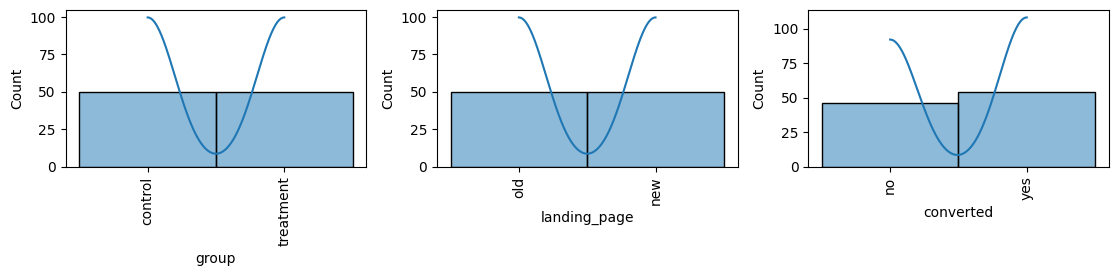

In [ ]:
# defining the figure size
plt.figure(figsize=(15, 10))

# defining the list of numerical features to plot
num_features = Newspaper[['group','landing_page','converted']]

# plotting the histogram for each numerical feature
for i, feature in enumerate(num_features):
    plt.subplot(4, 4, i+1)    # assign a subplot in the main plot
    sns.histplot(data=Newspaper, x=feature,kde=True)
    plt.xticks(rotation=90)
plt.tight_layout();   # to add spacing between plots

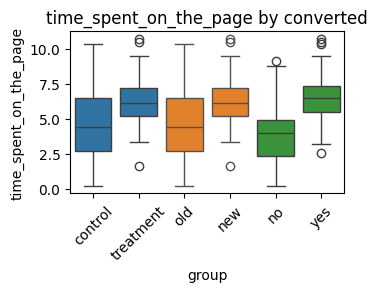

In [ ]:
# Only numerical columns
num_cols = Newspaper[['time_spent_on_the_page']]
cat_cols = Newspaper[['group','landing_page','converted']]


for num_col in num_cols:
    for cat_col in cat_cols:
        plt.subplot(2, 2, i+1)
        sns.boxplot(data=Newspaper, x=cat_col, y=num_col)
        plt.title(f'{num_col} by {cat_col}')
        plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

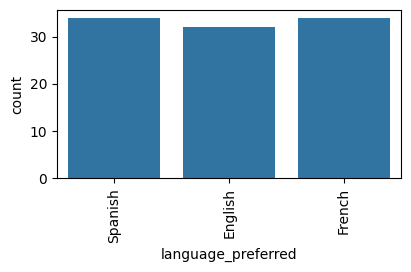

In [ ]:
# defining the figure size
plt.figure(figsize=(15, 10))

# defining the list of numerical features to plot
num_features = Newspaper[['language_preferred']]

# plotting the histogram for each numerical feature
for i, feature in enumerate(num_features):
    plt.subplot(4, 4, i+1)    # assign a subplot in the main plot
    sns.countplot(data=Newspaper, x=feature)
    plt.xticks(rotation=90)
plt.tight_layout();   # to add spacing between plots

The countplot shows us that readers prefers articles in Spanish and French when comparing with readers whose prefered language for the articles is English

With the countplot data it seems majority of readers prefer Spanish and French

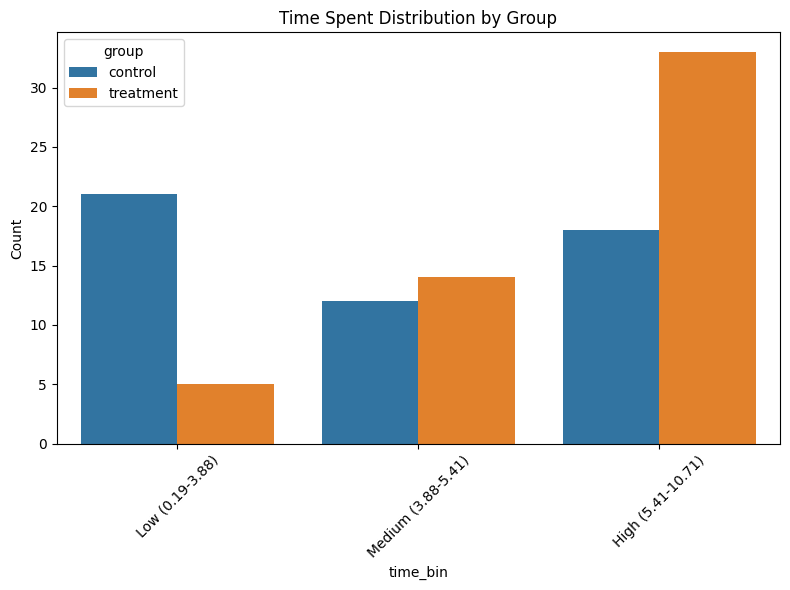

In [ ]:
Newspaper1 = Newspaper.copy()
time = Newspaper1[Newspaper1['time_spent_on_the_page'].between(0.19, 3.88)]
time1 = Newspaper1[Newspaper1['time_spent_on_the_page'].between(3.88, 5.41)]
time2 = Newspaper1[Newspaper1['time_spent_on_the_page'].between(5.41, 10.71)]

time_spent = pd.concat([
    time.assign(time_bin='Low (0.19-3.88)'),
    time1.assign(time_bin='Medium (3.88-5.41)'),
    time2.assign(time_bin='High (5.41-10.71)')
], ignore_index=True)


plt.figure(figsize=(8, 6))
sns.countplot(data=time_spent, x='time_bin', hue='group')
plt.title('Time Spent Distribution by Group')
plt.xticks(rotation=45)
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# **Data Preprocessing**

In [ ]:
Newspaper.drop(['user_id'],axis = 1, inplace=True)
Newspaper.head()

,group,landing_page,time_spent_on_the_page,converted,language_preferred
0,control,old,3.48,no,Spanish
1,treatment,new,7.13,yes,English
2,treatment,new,4.40,no,Spanish
3,control,old,3.02,no,French
4,treatment,new,4.75,yes,Spanish


## To get better descriptive statistics and data distribution between the columns, categorical columns values are replaced with numerical

In [ ]:
print('The online news portal of E-news Express consists of news based on',Newspaper['group'].unique())
Group = {"control": 0, "treatment": 1}
Newspaper["group"] = Newspaper["group"].map(Group)

The online news portal of E-news Express consists of news based on ['control' 'treatment']


* The online news portal of E-news Express consists of news based on two groups those are "control" and "treatment"
* There are only two categorical values present in the given dataset and those values are 'control' & 'treatment'
* The categorical value of 'control' replaced as '0' in numerical value,
* The categorical value of 'treatment' replaced as '1' in numerical value

In [ ]:
print(' The online news portal of E-news Express has two portals to read the articles they are:',Newspaper['landing_page'].unique())
Visit = {"old": 0, "new": 1}
Newspaper["landing_page"] = Newspaper["landing_page"].map(Visit)

 The online news portal of E-news Express has two portals to read the articles they are: ['old' 'new']


* There are two online news portal of E-news Express one which is already existed and another one is newly created one
* There are only two categorical values for 'landing_page' column present in the given dataset and those values are 'old' & 'new'
* The categorical value of 'old' is replaced as '0' in numerical value,
* The categorical value of 'new' is replaced as '1' in numerical value

In [ ]:
Converted = {"no": 0, "yes": 1}
Newspaper["converted"] = Newspaper["converted"].map(Converted)

* There are only two categorical values for 'converted' column which represent reader is using old portal or new portal in the given dataset and those values are 'old' & 'new'
* The categorical value of 'old' is replaced as '0' in numerical value,
* The categorical value of 'new' is replaced as '1' in numerical value

In [ ]:
print(' The online news portal of E-news Express comes in three languages to read the articles they are:',Newspaper['language_preferred'].unique())
Language = {"Spanish": 0, "English": 1, "French": 2}
Newspaper["language_preferred"] = Newspaper["language_preferred"].map(Language)

 The online news portal of E-news Express comes in three languages to read the articles they are: ['Spanish' 'English' 'French']


* The online news portal of E-news Express comes in three languages ant those languages are "Englisg", "French", "Spanish"
* The categorical value of 'Spanish' replaced as '0' in numerical value,
* The categorical value of 'English' replaced as '1' in numerical value,
* The categorical value of 'French' replaced as '2' in numerical value,

In [ ]:
Newspaper.head()

,group,landing_page,time_spent_on_the_page,converted,language_preferred
0,0,0,3.48,0,0
1,1,1,7.13,1,1
2,1,1,4.40,0,0
3,0,0,3.02,0,2
4,1,1,4.75,1,0


By checking the first five values in the dataset, i came to know that the values in the categorical columns are converted into numerical values

In [ ]:
Newspaper.describe()

,group,landing_page,time_spent_on_the_page,converted,language_preferred
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,0.500000,0.500000,5.377800,0.540000,1.000000
std,0.502519,0.502519,2.378166,0.500908,0.828775
min,0.000000,0.000000,0.190000,0.000000,0.000000
25%,0.000000,0.000000,3.880000,0.000000,0.000000
50%,0.500000,0.500000,5.415000,1.000000,1.000000
75%,1.000000,1.000000,7.022500,1.000000,2.000000
max,1.000000,1.000000,10.710000,1.000000,2.000000


* The given dataset is a perfectly balanced dataset
* The mean of the 'group' column and 'landing_page' column in the given dataset is 50 which means the dataset is split in equal half
*  The minimum time spent by the readers is "0.19" which is 19 secs in the "old" portal with the preferred language as "Spanish".
* The Average time spent by the readers is "5.41" which is 5 minutes 41 seconds in the "new" portal with the preferred language as "English".
* The Maximum time spent by the readers is "10.71" which is 11 minutes 11 seconds in the "new" portal with the preferred language as "French".


# **EDA Continues**

Bivariate analysis

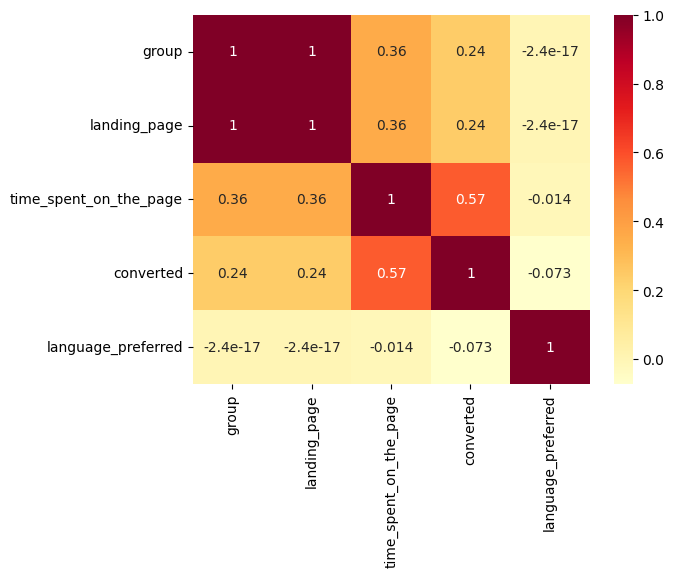

In [ ]:
sns.heatmap(data = Newspaper[['group','landing_page','time_spent_on_the_page','converted','language_preferred']].corr(), annot = True, cmap = 'YlOrRd');

Based on the Bi variate analysis:

* when comparing column "group" with column "time_spent_on_the_page" I have found that time spent on Treatment greater than time spent on Control.

* Treatment group spends ~2+ min more than Control group

* when comparing column "time_spent_on_the_page" with column "converted" I have found that reader who spent more they converted to new portal

* Higher time_spent_on_the_page then higher converted

* when comparing column "language" with column "converted" I have found that reader who prefer language as "French" mostly converted to new portal

In [ ]:
Group = {0:"control", 1: "treatment"}
Newspaper["group"] = Newspaper["group"].map(Group)
#print(Newspaper['group'].head())

Visit = {0:"old", 1: "new"}
Newspaper["landing_page"] = Newspaper["landing_page"].map(Visit)
#print(Newspaper['landing_page'].head())


Converted = {0:"no", 1:"yes"}
Newspaper["converted"] = Newspaper["converted"].map(Converted)
#print(Newspaper['converted'].head())

Language = {0:"Spanish", 1: "English", 2: "French"}
Newspaper["language_preferred"] = Newspaper["language_preferred"].map(Language)
#print(Newspaper['language_preferred'].head())

# **Do the users spend more time on the new landing page than the old landing page?**

/tmp/ipykernel_504/1098808873.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([non_converted, converted], labels=['Non-Converted', 'Converted'])


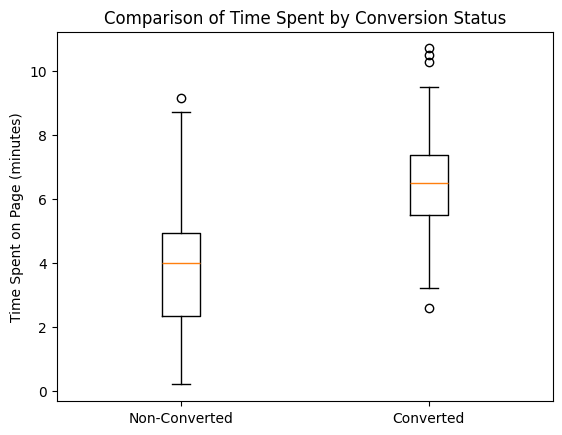

T statistic: 6.8717
p-value: 0.0000
Reject H0: Converted users spend significantly more time on the page.


In [ ]:
# Separate time spent data by conversion status
non_converted = Newspaper[Newspaper['converted'] == 'no']['time_spent_on_the_page']
converted = Newspaper[Newspaper['converted'] == 'yes']['time_spent_on_the_page']

# Visual analysis
plt.boxplot([non_converted, converted], labels=['Non-Converted', 'Converted'])
plt.ylabel("Time Spent on Page (minutes)")
plt.title("Comparison of Time Spent by Conversion Status")
plt.show()

# Hypothesis test
alpha = 0.05
t_stat, p_value = stats.ttest_ind(converted, non_converted, alternative='greater')

print(f"T statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.4f}")

if p_value < alpha:
    print("Reject H0: Converted users spend significantly more time on the page.")
else:
    print("Fail to reject H0: No significant evidence that converted users spend more time.")


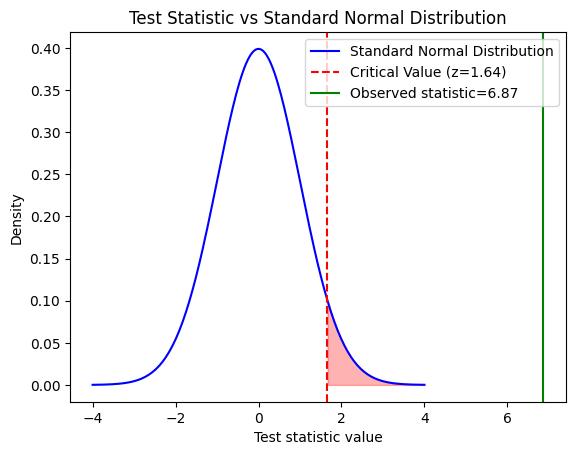

In [ ]:
t_stat = 6.87   # replace with the actual value you printed

# For large samples, the t distribution approaches the standard normal,
# so we can visualize it against the normal curve.
x = np.linspace(-4, 4, 200)
y = norm.pdf(x, 0, 1)

# Plot the standard normal distribution
plt.plot(x, y, 'b-', label='Standard Normal Distribution')

# Critical value for one-tailed test at alpha=0.05
critical_value = norm.ppf(0.95)
plt.axvline(critical_value, color='red', linestyle='--', label=f'Critical Value (z={critical_value:.2f})')

# Mark your observed test statistic
plt.axvline(t_stat, color='green', linestyle='-', label=f'Observed statistic={t_stat:.2f}')

# Shade rejection region
plt.fill_between(x, 0, y, where=(x > critical_value), color='red', alpha=0.3)

plt.title("Test Statistic vs Standard Normal Distribution")
plt.xlabel("Test statistic value")
plt.ylabel("Density")
plt.legend()
plt.show()

Observation:


**Time Spent on Page**
* Null Hypothesis (H₀): Conversion rate on new page ≤ conversion rate on old page
* Alternative Hypothesis (H₁): Conversion rate on new page > conversion rate on old page
* Appropriate Test: So appropriate test is two-proportion z-test

* In old page Control groups  Mean time is 4.93 minutes and in new page Treatment groups Mean time ≈ 6.23 minutes thus Independent two-sample t-test (one-tailed, H₁: new > old)
* Since p-value < 0.05, we reject H₀.

**Yes, users spend significantly more time on the new landing page compared to the old one.**



---------------------------------------------------
________________________________________________

# Is the conversion rate (the proportion of users who visit the landing page and get converted) for the new page greater than the conversion rate for the old page?


=== Conversion Rate Test ===
In the control group the percentage of users who converted to new landing page are :  42.0 %
In the treatment group the percentage of users who converted to new landing page are : 66.0 %


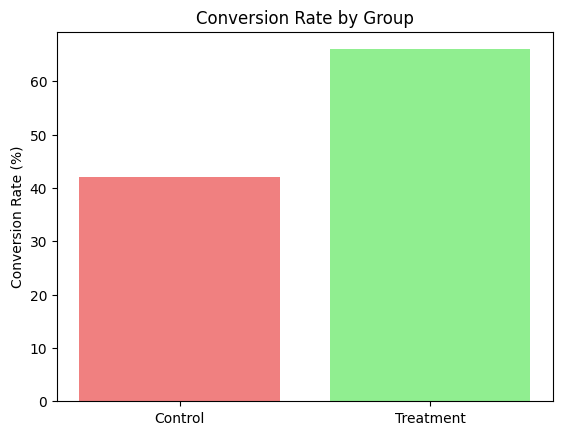




Z statistic: 2.4077
p-value: 0.0080



Conclusion at 5% significance level:
Reject H0. There is statistically significant evidence that
the new landing page has a higher subscription rate than the old page.


In [ ]:
# Total users by group
total_control = Newspaper[Newspaper['group'] == 'control'].shape[0]
total_treatment = Newspaper[Newspaper['group'] == 'treatment'].shape[0]

# Converted counts by group
converted_control = Newspaper[(Newspaper['group'] == 'control') & (Newspaper['converted'] == 'yes')].shape[0]
converted_treatment = Newspaper[(Newspaper['group'] == 'treatment') & (Newspaper['converted'] == 'yes')].shape[0]

# Conversion rates
print("\n=== Conversion Rate Test ===")
conversion_rate_control = converted_control / total_control
print("In the control group the percentage of users who converted to new landing page are : ",conversion_rate_control*100,'%')
conversion_rate_treatment = converted_treatment / total_treatment
print("In the treatment group the percentage of users who converted to new landing page are :",conversion_rate_treatment*100,'%')

# Perform visual analysis
plt.bar(['Control', 'Treatment'],
        [conversion_rate_control * 100, conversion_rate_treatment * 100],
        color=['lightcoral','lightgreen'])
plt.ylabel("Conversion Rate (%)")
plt.title("Conversion Rate by Group")
plt.show()


alpha = 0.05

# Data preparation
counts = np.array([converted_treatment, converted_control])
nobs   = np.array([total_treatment, total_control])

# alternative='larger' now corresponds to H1: p_treatment > p_control
z_stat, p_value = sm.stats.proportions_ztest(count=counts, nobs=nobs, alternative='larger')

print('\n\n')
print(f"Z statistic: {z_stat:.4f}")
print(f"p-value: {p_value:.4f}")
print('\n\n')

if p_value < alpha:
    print("Conclusion at 5% significance level:")
    print("Reject H0. There is statistically significant evidence that")
    print("the new landing page has a higher subscription rate than the old page.")
else:
    print("Conclusion at 5% significance level:")
    print("Fail to reject H0. There is not enough statistical evidence to conclude")
    print("that the new landing page has a higher subscription rate than the old page.")

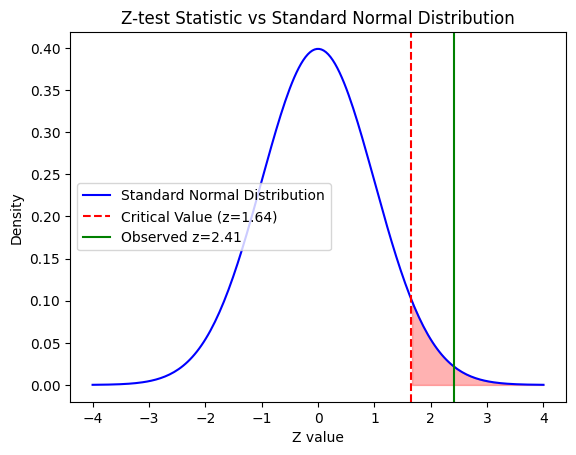

In [ ]:
# Your observed z-statistic
z_stat = 2.4077

# Create range of values for the standard normal curve
x = np.linspace(-4, 4, 200)
y = norm.pdf(x, 0, 1)

# Plot the standard normal distribution
plt.plot(x, y, 'b-', label='Standard Normal Distribution')

# Shade the rejection region (right tail, alpha=0.05)
critical_value = norm.ppf(0.95)  # one-tailed test at 5% significance
plt.axvline(critical_value, color='red', linestyle='--', label=f'Critical Value (z={critical_value:.2f})')

# Mark your observed z-statistic
plt.axvline(z_stat, color='green', linestyle='-', label=f'Observed z={z_stat:.2f}')

# Fill the rejection region
plt.fill_between(x, 0, y, where=(x > critical_value), color='red', alpha=0.3)

plt.title("Z-test Statistic vs Standard Normal Distribution")
plt.xlabel("Z value")
plt.ylabel("Density")
plt.legend()
plt.show()

Observation:

**Conversion Rate**

* Control group conversions: 26 out of 50 (42%)

* Treatment group conversions: 33 out of 50 (66%)

* Test used: Two-proportion z-test (one-tailed, H₁: p_treatment > p_control)

* Since p-value > 0.008, we reject H₀.

 **There is statistically significant evidence that the new page has a higher subscription rate than the old page.**

# Does the converted status depend on the preferred language?

Contingency Table:
 converted           no  yes
language_preferred         
English             11   21
French              19   15
Spanish             16   18


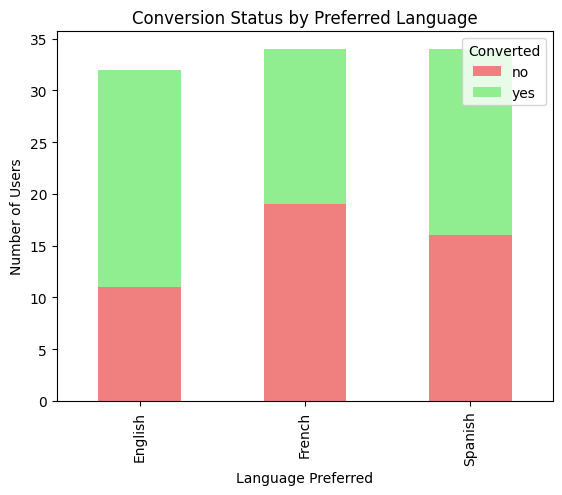


Chi-square Statistic: 3.0930306905370832
Degrees of Freedom: 2
p-value: 0.2129888748754345

Conclusion: Fail to reject H0.
No significant evidence that conversion status depends on preferred language.


In [ ]:
# Build contingency table: counts of converted vs not converted by language
contingency_table = pd.crosstab(Newspaper['language_preferred'], Newspaper['converted'])
print("Contingency Table:\n", contingency_table)


# visual analysis
contingency_table.plot(kind='bar', stacked=True, color=['lightcoral','lightgreen'])
plt.title("Conversion Status by Preferred Language")
plt.xlabel("Language Preferred")
plt.ylabel("Number of Users")
plt.legend(title="Converted")
plt.show()

# Perform chi-square test of independence
chi2, p, dof, expected = chi2_contingency(contingency_table)

print("\nChi-square Statistic:", chi2)
print("Degrees of Freedom:", dof)
print("p-value:", p)

# Inference
alpha = 0.05
if p < alpha:
    print("\nConclusion: Reject H0.")
    print("Conversion status depends on preferred language.")
else:
    print("\nConclusion: Fail to reject H0.")
    print("No significant evidence that conversion status depends on preferred language.")

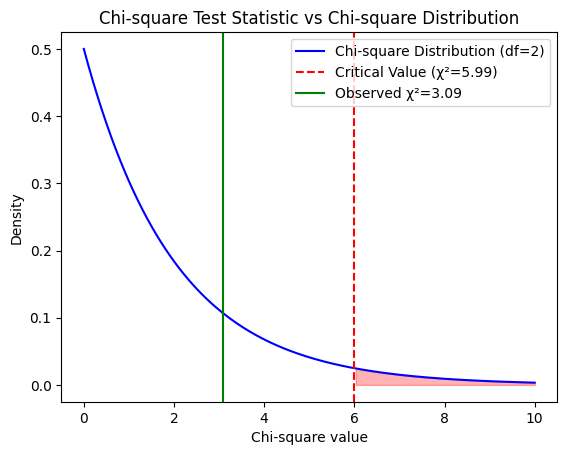

In [ ]:
# Your computed chi-square statistic and degrees of freedom
chi2_stat = 3.093
dof = 2

# Generate x values and Chi-square PDF values
x = np.linspace(0, 10, 200)
y = stats.chi2.pdf(x, df=dof)   # use stats.chi2.pdf for the chi-square distribution

# Plot the Chi-square distribution curve
plt.plot(x, y, 'b-', label=f'Chi-square Distribution (df={dof})')

# Critical value for alpha=0.05
critical_value = stats.chi2.ppf(0.95, df=dof)
plt.axvline(critical_value, color='red', linestyle='--',
            label=f'Critical Value (χ²={critical_value:.2f})')

# Mark your observed chi-square statistic
plt.axvline(chi2_stat, color='green', linestyle='-',
            label=f'Observed χ²={chi2_stat:.2f}')

# Shade rejection region (right tail beyond critical value)
plt.fill_between(x, 0, y, where=(x > critical_value), color='red', alpha=0.3)

# Add labels and legend
plt.title("Chi-square Test Statistic vs Chi-square Distribution")
plt.xlabel("Chi-square value")
plt.ylabel("Density")
plt.legend()
plt.show()

Observation:

* Since p‑value (0.213) > 0.05, we fail to reject H₀.

* This means there is no statistically significant evidence that conversion status depends on preferred language.

* these differences are small relative to the sample size. Statistically, they could easily be due to chance. So, language preference does not appear to influence whether a user converts.

* The stacked bar chart shows similar proportions of converted vs non‑converted users across English, French, and Spanish.

* No language group stands out as having a dramatically higher or lower conversion rate.

# Is the mean time spent on the new page same for the different language users?

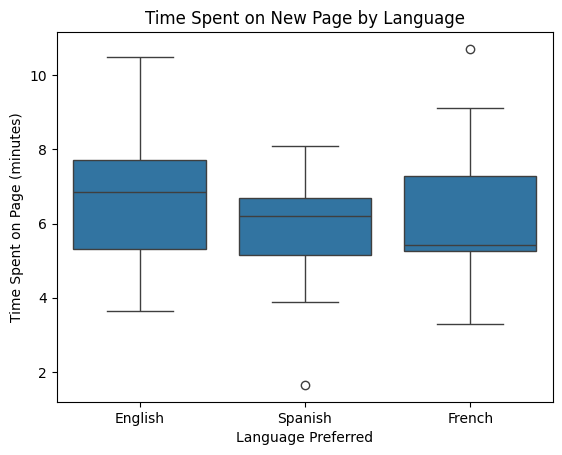

F-statistic: 0.8543992770006822
p-value: 0.43204138694325955

Conclusion: Fail to reject H0.
No significant evidence that mean time spent differs across languages.


In [ ]:
new_page = Newspaper[Newspaper['landing_page'] == 'new']

# Data Collection & Preparation
english_times = new_page[new_page['language_preferred'] == 'English']['time_spent_on_the_page']
french_times = new_page[new_page['language_preferred'] == 'French']['time_spent_on_the_page']
spanish_times = new_page[new_page['language_preferred'] == 'Spanish']['time_spent_on_the_page']


# Visualize analysis
sns.boxplot(x='language_preferred', y='time_spent_on_the_page', data=new_page)
plt.title("Time Spent on New Page by Language")
plt.xlabel("Language Preferred")
plt.ylabel("Time Spent on Page (minutes)")
plt.show()


# Perform one-way ANOVA
f_stat, p_value = f_oneway(english_times, french_times, spanish_times)

print("F-statistic:", f_stat)
print("p-value:", p_value)

# Inference
alpha = 0.05
if p_value < alpha:
    print("\nConclusion: Reject H0.")
    print("Mean time spent differs significantly across languages.")
else:
    print("\nConclusion: Fail to reject H0.")
    print("No significant evidence that mean time spent differs across languages.")

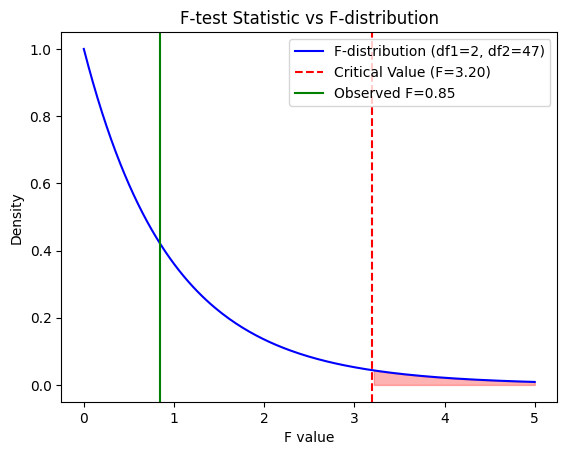

In [ ]:
f_stat = 0.85   # example value, replace with your computed result
df_between = 2   # number of groups - 1 (English, French, Spanish → 3-1=2)
df_within = len(new_page) - 3   # total samples - number of groups

# Generate x values and F-distribution PDF values
x = np.linspace(0, 5, 200)
y = f.pdf(x, df_between, df_within)

# Plot the F-distribution curve
plt.plot(x, y, 'b-', label=f'F-distribution (df1={df_between}, df2={df_within})')

# Critical value for alpha=0.05
critical_value = f.ppf(0.95, df_between, df_within)
plt.axvline(critical_value, color='red', linestyle='--',
            label=f'Critical Value (F={critical_value:.2f})')

# Mark your observed F-statistic
plt.axvline(f_stat, color='green', linestyle='-',
            label=f'Observed F={f_stat:.2f}')

# Shade rejection region (right tail beyond critical value)
plt.fill_between(x, 0, y, where=(x > critical_value), color='red', alpha=0.3)

# Add labels and legend
plt.title("F-test Statistic vs F-distribution")
plt.xlabel("F value")
plt.ylabel("Density")
plt.legend()
plt.show()

Observation:

* Null hypothesis (H₀): The mean time spent on the new page is the same across English, French, and Spanish users.

* Alternative hypothesis (H₁): At least one language group has a different mean time spent on the new page.

* Since we are comparing means across more than two groups, the correct test is a one‑way ANOVA

* If p < 0.05 → Reject H₀ → mean time spent differs significantly across languages.

* If p ≥ 0.05 → Fail to reject H₀ → no evidence of difference; mean times are statistically similar.


**This means there is no significant evidence that the mean time spent on the new page differs across English, French, and Spanish users.**